# 02: Keşifsel analiz ve testler

Burada kendi puanlarıma bakıp şu soruların cevabını arıyorum: hangi tür, dönem ve ülkelere daha yüksek puan veriyorum, TMDB'nin ortalamasıyla ne kadar örtüşüyorum, zevkim zamanla değişti mi?

Elimde 355 puanlı film var. Bu az bir sayı, o yüzden her karşılaştırmada grup büyüklüklerini yazıyorum. Puanlar yarım yarım artan sıralı bir ölçek olduğu için t testi yerine parametrik olmayan testleri (Kruskal-Wallis, Mann-Whitney, Spearman) kullanıyorum. Aynı veride çok sayıda tür test edeceğim, bu yüzden p değerlerini Benjamini-Hochberg ile düzeltiyorum.

Girdi: `data/processed/analysis_table.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
from statsmodels.stats.multitest import multipletests

ROOT = Path('..').resolve()
FIG = ROOT / 'reports' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(42)

df = pd.read_csv(ROOT / 'data' / 'processed' / 'analysis_table.csv', parse_dates=['rated_date'])
genre_cols = [c for c in df.columns if c.startswith('g_')]
print(df.shape)

def boot_ci(x, n=5000, alpha=0.05):
    x = np.asarray(x)
    means = rng.choice(x, size=(n, len(x)), replace=True).mean(axis=1)
    return np.quantile(means, [alpha / 2, 1 - alpha / 2])

(355, 49)


## 1. Puanların dağılımı

count    355.00
mean       3.66
std        0.91
min        0.50
25%        3.00
50%        4.00
75%        4.50
max        5.00
Name: rating, dtype: float64

Ortanca: 4.0 | Ortalamanın %95 bootstrap aralığı: [3.57 3.76]


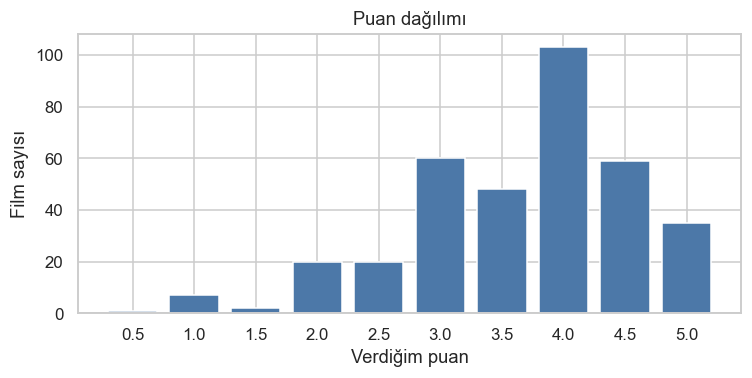

In [2]:
print(df['rating'].describe().round(2))
print('\nOrtanca:', df['rating'].median(), '| Ortalamanın %95 bootstrap aralığı:', boot_ci(df['rating']).round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
order = np.arange(0.5, 5.5, 0.5)
counts = df['rating'].value_counts().reindex(order, fill_value=0)
ax.bar(order, counts.values, width=0.4, color='#4c78a8')
ax.set_xticks(order)
ax.set_xlabel('Verdiğim puan')
ax.set_ylabel('Film sayısı')
ax.set_title('Puan dağılımı')
fig.tight_layout()
fig.savefig(FIG / '01_puan_dagilimi.png')
plt.show()

## 2. On yıllara göre

1980 öncesini tek grupta topluyorum, o yıllardan çok az film izlemişim.

       count  mean  median
<1980     19  4.37    4.50
1980s     12  4.33    4.25
1990s     54  4.15    4.00
2000s     77  3.87    4.00
2010s    131  3.49    3.50
2020s     62  3.02    3.00

Kruskal-Wallis: H = 74.89, p = 0.000


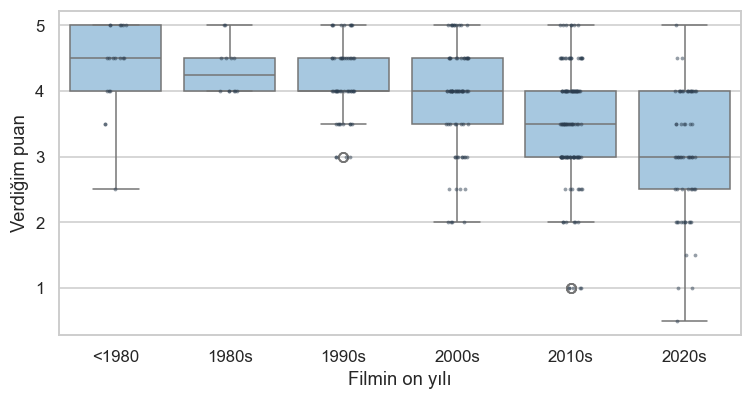

In [3]:
df['decade_grp'] = df['decade'].where(df['decade'] >= 1980, 1970).astype(int)
dec = df.groupby('decade_grp')['rating'].agg(['count', 'mean', 'median']).round(2)
dec.index = ['<1980' if d == 1970 else f'{d}s' for d in dec.index]
print(dec)

groups = [g['rating'].values for _, g in df.groupby('decade_grp')]
H, p = stats.kruskal(*groups)
print(f'\nKruskal-Wallis: H = {H:.2f}, p = {p:.3f}')

fig, ax = plt.subplots(figsize=(7, 3.8))
sns.boxplot(data=df, x='decade_grp', y='rating', color='#9ecae9', ax=ax)
sns.stripplot(data=df, x='decade_grp', y='rating', color='#2c3e50', size=2.5, alpha=0.5, ax=ax)
ax.set_xticks(range(len(dec)))
ax.set_xticklabels(dec.index)
ax.set_xlabel('Filmin on yılı')
ax.set_ylabel('Verdiğim puan')
fig.tight_layout()
fig.savefig(FIG / '02_on_yil.png')
plt.show()

## 3. Türlere göre

Bir filmin birden fazla türü olduğu için gruplar birbirinden bağımsız değil. Her türü "o türdeki filmler ile geri kalanlar" diye karşılaştırıyorum. En az 15 filmi olan türlere bakıyorum.

            tür   n   ort  ci_alt  ci_ust  diğerlerinin_ort   fark     p  p_düz
      Animation  23 4.261   4.065   4.457             3.623  0.637 0.001  0.004
          Crime  54 3.954   3.731   4.176             3.613  0.341 0.008  0.017
         Family  20 3.900   3.525   4.225             3.651  0.249 0.172  0.286
        History  16 3.875   3.469   4.219             3.655  0.220 0.394  0.537
          Drama 206 3.842   3.733   3.951             3.419  0.423 0.000  0.001
        Mystery  36 3.819   3.486   4.125             3.647  0.172 0.145  0.272
        Romance  48 3.750   3.531   3.958             3.651  0.099 0.745  0.798
            War  17 3.706   3.324   4.088             3.663  0.043 0.950  0.950
        Fantasy  44 3.659   3.341   3.955             3.666 -0.007 0.722  0.798
       Thriller  82 3.628   3.433   3.823             3.676 -0.048 0.727  0.798
         Comedy  56 3.571   3.366   3.777             3.682 -0.111 0.215  0.322
      Adventure  72 3.361   3.132   3.59

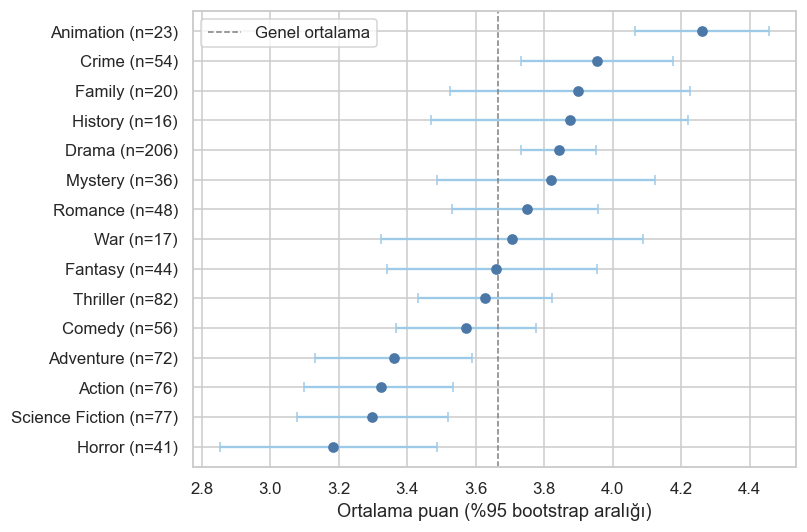

In [4]:
rows = []
for c in genre_cols:
    mask = df[c] == 1
    n = int(mask.sum())
    if n < 15:
        continue
    a, b = df.loc[mask, 'rating'], df.loc[~mask, 'rating']
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    lo, hi = boot_ci(a)
    rows.append({'tür': c[2:], 'n': n, 'ort': a.mean(), 'ci_alt': lo, 'ci_ust': hi,
                 'diğerlerinin_ort': b.mean(), 'fark': a.mean() - b.mean(), 'p': p})
gen = pd.DataFrame(rows)
gen['p_düz'] = multipletests(gen['p'], method='fdr_bh')[1]
gen = gen.sort_values('ort', ascending=False).reset_index(drop=True)
print(gen.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(gen))[::-1]
ax.errorbar(gen['ort'], y, xerr=[gen['ort'] - gen['ci_alt'], gen['ci_ust'] - gen['ort']],
            fmt='o', color='#4c78a8', ecolor='#9ecae9', capsize=3)
ax.axvline(df['rating'].mean(), color='gray', ls='--', lw=1, label='Genel ortalama')
ax.set_yticks(y)
ax.set_yticklabels([f"{t} (n={n})" for t, n in zip(gen['tür'], gen['n'])])
ax.set_xlabel('Ortalama puan (%95 bootstrap aralığı)')
ax.legend()
fig.tight_layout()
fig.savefig(FIG / '03_turler.png')
plt.show()

## 4. Benim puanım ve TMDB puanı

Kalabalığın beğendiği filmleri ben de mi beğeniyorum? Spearman korelasyonuyla bakıyorum.

           değişken    rho  ci_alt  ci_ust     p  p_düz
TMDB ortalama puanı  0.599   0.521   0.667 0.000  0.000
      log oy sayısı  0.110   0.006   0.212 0.038  0.057
     log popülerlik  0.188   0.088   0.290 0.000  0.001
          süre (dk)  0.091  -0.019   0.200 0.086  0.103
          film yılı -0.475  -0.554  -0.390 0.000  0.000
         tür sayısı -0.062  -0.163   0.042 0.241  0.241


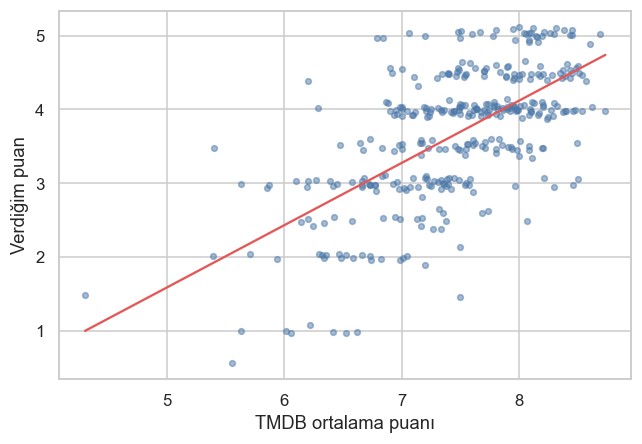

In [5]:
cands = {'TMDB ortalama puanı': 'tmdb_vote_average', 'log oy sayısı': 'log_votes',
         'log popülerlik': 'log_popularity', 'süre (dk)': 'runtime', 'film yılı': 'year',
         'tür sayısı': 'n_genres'}
res = []
for label, col in cands.items():
    sub = df[['rating', col]].dropna()
    r, p = stats.spearmanr(sub['rating'], sub[col])
    # bootstrap aralığı
    idx = rng.integers(0, len(sub), size=(2000, len(sub)))
    rs = [stats.spearmanr(sub['rating'].values[i], sub[col].values[i])[0] for i in idx]
    res.append({'değişken': label, 'rho': r, 'ci_alt': np.quantile(rs, .025), 'ci_ust': np.quantile(rs, .975), 'p': p})
corr = pd.DataFrame(res)
corr['p_düz'] = multipletests(corr['p'], method='fdr_bh')[1]
print(corr.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4.2))
jit = rng.normal(0, 0.06, len(df))
ax.scatter(df['tmdb_vote_average'], df['rating'] + jit, s=14, alpha=0.5, color='#4c78a8')
m, b = np.polyfit(df['tmdb_vote_average'], df['rating'], 1)
xs = np.linspace(df['tmdb_vote_average'].min(), df['tmdb_vote_average'].max(), 50)
ax.plot(xs, m * xs + b, color='#e45756')
ax.set_xlabel('TMDB ortalama puanı')
ax.set_ylabel('Verdiğim puan')
fig.tight_layout()
fig.savefig(FIG / '04_tmdb_vs_ben.png')
plt.show()

## 5. İngilizce ve diğer diller

In [6]:
eng = df.loc[df['is_english'] == 1, 'rating']
non = df.loc[df['is_english'] == 0, 'rating']
print(f'İngilizce: n={len(eng)}, ort={eng.mean():.2f} | Diğer: n={len(non)}, ort={non.mean():.2f}')
u, p = stats.mannwhitneyu(eng, non)
print(f'Mann-Whitney U={u:.0f}, p={p:.3f}')
print('\nEn çok izlediğim diller:')
print(df.groupby('original_language')['rating'].agg(['count', 'mean']).sort_values('count', ascending=False).head(6).round(2))

İngilizce: n=283, ort=3.60 | Diğer: n=72, ort=3.93
Mann-Whitney U=7632, p=0.001

En çok izlediğim diller:
                   count  mean
original_language             
en                   283  3.60
tr                    26  3.54
ja                    12  4.42
fr                     9  4.22
fa                     4  4.38
de                     4  4.12


## 6. Zaman içinde: zevkim değişti mi?

Puanladığım yıla göre ortalamaya bakıyorum. Ayrıca puanladığım filmlerin yaşı değişti mi diye de bakıyorum. 2022 kayıtları Aralık ayı, 2026 ise yılın sadece bir kısmı.

              n   ort  film_yili_ort
rated_year                          
2022         46  3.78         2007.0
2023        132  3.44         2014.0
2024         88  3.72         2011.0
2025         63  3.96         2004.0
2026         26  3.69         2014.0

Kruskal-Wallis (puanlama yılına göre): H=17.12, p=0.002
Spearman (tarih, puan): rho=0.088, p=0.097


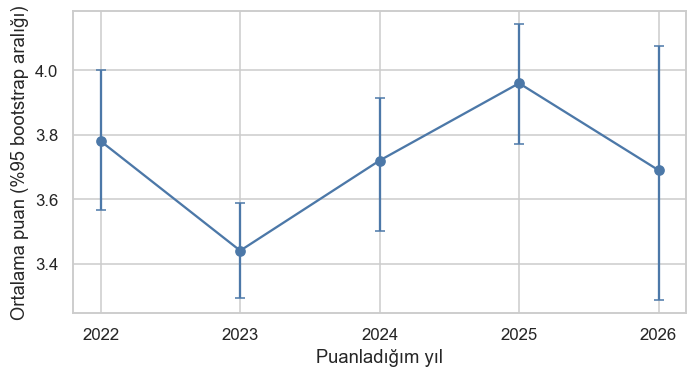

In [7]:
yr = df.groupby('rated_year').agg(n=('rating', 'size'), ort=('rating', 'mean'),
                                  film_yili_ort=('year', 'median')).round(2)
print(yr)
H, p = stats.kruskal(*[g['rating'].values for _, g in df.groupby('rated_year')])
print(f'\nKruskal-Wallis (puanlama yılına göre): H={H:.2f}, p={p:.3f}')
r, p = stats.spearmanr(df['rated_date'].map(pd.Timestamp.toordinal), df['rating'])
print(f'Spearman (tarih, puan): rho={r:.3f}, p={p:.3f}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ci = [boot_ci(g['rating']) for _, g in df.groupby('rated_year')]
ax.errorbar(yr.index, yr['ort'], yerr=[yr['ort'] - [c[0] for c in ci], [c[1] for c in ci] - yr['ort']],
            fmt='o-', color='#4c78a8', capsize=3)
ax.set_xticks(yr.index)
ax.set_xlabel('Puanladığım yıl')
ax.set_ylabel('Ortalama puan (%95 bootstrap aralığı)')
fig.tight_layout()
fig.savefig(FIG / '05_zaman.png')
plt.show()

## 7. Kalp verdiğim filmler puanlarımla tutarlı mı?

In [8]:
print(df.groupby('rating')['liked'].agg(['count', 'mean']).round(2).T)
print('\nKalpli filmlerin ortalaması:', round(df.loc[df['liked'] == 1, 'rating'].mean(), 2),
      '| kalpsizlerin:', round(df.loc[df['liked'] == 0, 'rating'].mean(), 2))
print('Puan 4 ve üstü olup kalpsiz film sayısı:', int(((df['rating'] >= 4) & (df['liked'] == 0)).sum()))

rating  0.5  1.0  1.5   2.0   2.5   3.0   3.5     4.0    4.5    5.0
count   1.0  7.0  2.0  20.0  20.0  60.0  48.0  103.00  59.00  35.00
mean    0.0  0.0  0.0   0.0   0.0   0.0   0.0    0.08   0.63   0.91

Kalpli filmlerin ortalaması: 4.66 | kalpsizlerin: 3.39
Puan 4 ve üstü olup kalpsiz film sayısı: 120


## 8. Ne çıktı?

Rakamlar yukarıdaki hücrelerden. n küçük olduğu için aralıklar geniş, bunları kesin hüküm gibi okumuyorum.

**Eski filmlere daha iyi puan veriyorum.** Ortalamam 1980 öncesinde 4,37, 1990'larda 4,15, 2000'lerde 3,87, 2010'larda 3,49 ve 2020'lerde 3,02. Kruskal-Wallis bunun tesadüf olmadığını gösteriyor (H = 74,9, p < 0,001) ve film yılı ile puan arasındaki Spearman korelasyonu -0,48. Bunun bir kısmı seçilim olabilir: eski filmlerden zaten listelerde övülenleri izliyorum, yeni filmleri ise gelişigüzel açıyorum. Bu yüzden "eski film iyidir" demek yerine "eski filmlerde seçici davranıyorum" demek daha doğru.

**Türler.** Düzeltilmiş p değerine göre Animation (4,26), Crime (3,95) ve Drama (3,84) geri kalanlardan yüksek. Horror (3,18), Science Fiction (3,30), Action (3,32) ve Adventure (3,36) düşük. Romance, Thriller, Comedy, Fantasy, War, History, Mystery ve Family farklı çıkmadı. Horror'da 41 film var ve aralık geniş (2,85 ile 3,49 arası), orada temkinli olmak lazım.

**TMDB ile örtüşüyorum.** Benim puanım ile TMDB ortalaması arasında Spearman rho = 0,60 (%95 aralık 0,52 ile 0,67). Oy sayısıyla ilişki zayıf (0,11), popülerlikle biraz daha fazla (0,19). Süre ve tür sayısı belirgin bir ilişki göstermedi.

**Yabancı dilde puanlarım yüksek.** İngilizce filmlerde ortalamam 3,60, diğer dillerde 3,93 (Mann-Whitney p = 0,001). Japonca (n = 12) ve Fransızca (n = 9) örneklerinin ortalaması 4 üstünde ama bu gruplar küçük. Türkçe filmlerin ortalaması (n = 26) 3,54 ile İngilizceye yakın.

**Zaman içinde.** Puanlama yılına göre ortalamalar farklı (Kruskal-Wallis p = 0,002) ama düzenli bir yükseliş ya da düşüş yok: 2022'de 3,78, 2023'te 3,44, 2024'te 3,72, 2025'te 3,96. Tarih ile puan arasındaki Spearman korelasyonu 0,09 (p = 0,10). 2023'ün düşük çıkması o yıl daha çok yeni film izlememle de ilgili olabilir, çünkü film yılı ortancası o yıl 2014, 2025'te ise 2004.

**Kalp ve puan.** 4,5 puan verdiğim filmlerin %63'üne, 5 puan verdiğim filmlerin %91'ine kalp vermişim. 4 puanlıların sadece %8'inde kalp var. 4 ve üstü puan verip kalp vermediğim 120 film var, yani kalp "çok sevdim" anlamında kullanılıyor.

### Modelleme için çıkarımlar

- Film yılı ve TMDB puanı en güçlü iki aday özellik. Türler ile film yılı birbirine karışmış olabilir (sci-fi ve aksiyon yeni filmlerde daha sık), bunu modelde birlikte ele alacağım.
- 355 film az, bu yüzden tekrarlı çapraz doğrulama kullanacağım ve her modeli ortalama puanı tahmin eden basit bir temel çizgiyle karşılaştıracağım.
- Kalp bilgisini modele özellik olarak koymayacağım, çünkü puanla birlikte oluşan bir bilgi ve sızıntı yaratır.
